# ZeRO-1, ZeRO-2 and ZeRO-3 on 32 virtual GPUs

**ERA V5, Session 12 assignment.** Build a cluster of 32 virtual GPUs, train a small model on it, and simulate
ZeRO stages 1, 2 and 3 next to plain data parallelism (DDP). Measure how **memory per GPU**, **communication**
and **computation** change from stage to stage.

**How the virtual GPUs work.** Each virtual GPU is a thread with its own *rank* (0 to 31), its own copy (or slice) of the
model state, and its own **gloo** communicator. Ranks never touch each other's tensors. Everything they share goes through
real collectives over loopback TCP: `all_reduce`, `reduce_scatter` and `all_gather`. The code is in
[`zero_sim.py`](zero_sim.py). The forward and backward passes are written by hand, so you can read exactly where each
stage gathers, reduces and frees.

Why threads and not 32 processes? On Windows each process that imports the CUDA build of PyTorch reserves several GB of
virtual memory, and 32 of them exhausted the page file on this laptop. Threads share one copy of PyTorch, and NCCL needs one
physical GPU per rank, so the single GTX 1660 Ti can't host 32 ranks either. The collectives and the per-rank bookkeeping
work the same way with threads.

**Precision, following the course notes (16 bytes per parameter).**

| state | dtype | bytes / param |
|---|---|---|
| working weights (used in forward/backward) | bf16 | 2 |
| gradients | bf16 | 2 |
| master weights | fp32 | 4 |
| Adam first moment `m` | fp32 | 4 |
| Adam second moment `v` | fp32 | 4 |
| **total** | | **16** |

In [1]:
import os, json, platform
os.environ["TORCH_CPP_LOG_LEVEL"] = "ERROR"   # hide harmless Windows hostname warnings from c10d
import torch
import pandas as pd
import matplotlib.pyplot as plt
import zero_sim as z

os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
COLORS = {"ddp": "#7f7f7f", "zero1": "#1f77b4", "zero2": "#2ca02c", "zero3": "#d62728"}
CAT_COLORS = {"params": "#4c72b0", "gathered_params": "#a1c9f4", "grads": "#dd8452",
              "optimizer": "#55a868", "activations": "#c44e52"}
MiB = 2 ** 20

print("python  ", platform.python_version())
print("torch   ", torch.__version__)
print("CPU     ", platform.processor(), "|", os.cpu_count(), "logical cores")
print("GPU     ", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
      "(not used: NCCL needs one physical GPU per rank)")
print("backend  gloo available:", torch.distributed.is_gloo_available())

python   3.10.11
torch    2.14.1+cu126
CPU      Intel64 Family 6 Model 158 Stepping 10, GenuineIntel | 12 logical cores
GPU      NVIDIA GeForce GTX 1660 Ti (not used: NCCL needs one physical GPU per rank)
backend  gloo available: True


## 1. What the theory predicts

With $\Psi$ parameters and $N$ GPUs, each GPU holds the following (bytes):

| | weights (bf16) | grads (bf16) | optimizer (fp32 copy + m + v) | total per param | comm per step |
|---|---|---|---|---|---|
| DDP | $2\Psi$ | $2\Psi$ | $12\Psi$ | $16$ | $2P$ (all-reduce) |
| ZeRO-1 | $2\Psi$ | $2\Psi$ | $12\Psi/N$ | $4 + 12/N$ | $2P$ (reduce-scatter + all-gather) |
| ZeRO-2 | $2\Psi$ | $2\Psi/N$ | $12\Psi/N$ | $2 + 14/N$ | $2P$ (reduce-scatter + all-gather) |
| ZeRO-3 | $2\Psi/N$ | $2\Psi/N$ | $12\Psi/N$ | $16/N$ | $3P$ (2 all-gathers + reduce-scatter) |

$P = 2\Psi$ bytes is one bf16 copy of the weights. With ring collectives each GPU actually sends $(N-1)/N$ of these amounts,
so at $N = 32$ "2P" is really $1.94P$.

Here are those formulas applied to the 30B-parameter V5 model from the session. This reproduces the "memory ladder" table in the notes.

In [2]:
def gib_per_gpu(stage, n, params=30e9):
    return sum(z.bytes_per_param(stage, n).values()) * params / 2 ** 30

ladder = pd.DataFrame({f"{n} GPUs": [gib_per_gpu(s, n) for s in z.STAGES] for n in [8, 16, 32, 64]},
                      index=[z.STAGE_LABEL[s] for s in z.STAGES]).round(1)
ladder.insert(0, "bytes/param @ N=8", [round(sum(z.bytes_per_param(s, 8).values()), 2) for s in z.STAGES])
ladder.insert(1, "comm", ["2P", "2P", "2P", "3P"])
ladder

,bytes/param @ N=8,comm,8 GPUs,16 GPUs,32 GPUs,64 GPUs
DDP (no sharding),16.00,2P,447.0,447.0,447.0,447.0
ZeRO-1,5.50,2P,153.7,132.7,122.2,117.0
ZeRO-2,3.75,2P,104.8,80.3,68.1,62.0
ZeRO-3,2.00,3P,55.9,27.9,14.0,7.0


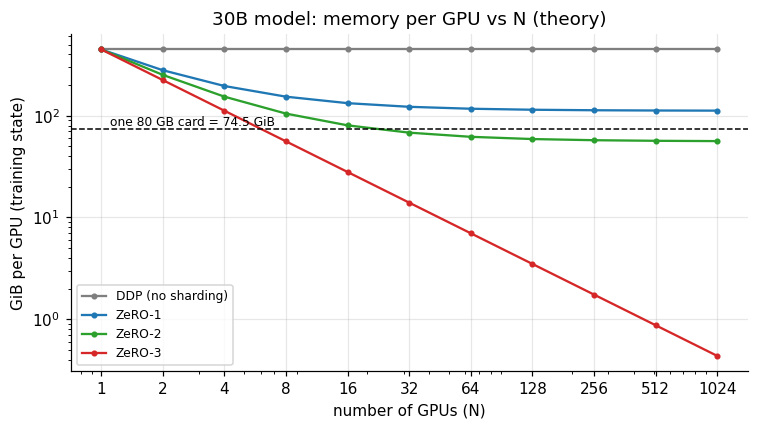

In [3]:
ns = [2 ** k for k in range(0, 11)]
fig, ax = plt.subplots(figsize=(7, 4))
for s in z.STAGES:
    ax.plot(ns, [gib_per_gpu(s, n) for n in ns], "o-", color=COLORS[s], label=z.STAGE_LABEL[s], ms=3)
ax.axhline(74.5, color="k", ls="--", lw=1)
ax.text(1.1, 80, "one 80 GB card = 74.5 GiB", fontsize=8)
ax.set(xscale="log", yscale="log", xlabel="number of GPUs (N)", ylabel="GiB per GPU (training state)",
       title="30B model: memory per GPU vs N (theory)")
ax.set_xticks(ns, [str(n) for n in ns])
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("results/theory_memory_wall_30B.png"); plt.show()

DDP and ZeRO-1 level off: they always keep a full copy of the weights and the gradients (4 bytes per parameter), and that part
doesn't shrink when you add GPUs. ZeRO-2 levels off at 2 bytes. Only ZeRO-3 keeps falling as $1/N$.

## 2. The virtual cluster and its three collectives

A 4-rank example first, so you can see what each collective returns. Rank $r$ starts with `[10r, 10r+1, 10r+2, 10r+3]`.

In [4]:
pd.DataFrame(z.demo_collectives(4)).set_index("rank")

,input,all_reduce,reduce_scatter,all_gather (input = [10r])
rank,,,,
0,"[0.0, 1.0, 2.0, 3.0]","[60.0, 64.0, 68.0, 72.0]",[60.0],"[0.0, 10.0, 20.0, 30.0]"
1,"[10.0, 11.0, 12.0, 13.0]","[60.0, 64.0, 68.0, 72.0]",[64.0],"[0.0, 10.0, 20.0, 30.0]"
2,"[20.0, 21.0, 22.0, 23.0]","[60.0, 64.0, 68.0, 72.0]",[68.0],"[0.0, 10.0, 20.0, 30.0]"
3,"[30.0, 31.0, 32.0, 33.0]","[60.0, 64.0, 68.0, 72.0]",[72.0],"[0.0, 10.0, 20.0, 30.0]"


* **all-reduce**: every rank ends with the full column-wise sum `[60, 64, 68, 72]`.
* **reduce-scatter**: rank $j$ ends with only element $j$ of that sum. Each rank owns one slice of the answer.
* **all-gather**: each rank contributes one value and every rank ends with all of them.

A reduce-scatter followed by an all-gather gives the same result as an all-reduce. That's why ZeRO-1 and ZeRO-2 cost no
more communication than DDP.

Now the same check on all 32 virtual GPUs:

In [5]:
out32 = z.demo_collectives(32)
expected = [sum(10 * r + j for r in range(32)) for j in range(32)]
print("all 32 ranks agree on the all-reduce:", all(o["all_reduce"] == expected for o in out32))
print("rank j got slice j of the reduce-scatter:", all(o["reduce_scatter"] == [expected[o["rank"]]] for o in out32))

all 32 ranks agree on the all-reduce: True
rank j got slice j of the reduce-scatter: True


## 3. The demo model

Six `Linear(512, 512)` layers with ReLU between them, trained with MSE on a synthetic regression task, $y = \sin(xA)$.
Each layer's weight and bias are stored as one flat vector (a "flat parameter", like FSDP), padded so it splits evenly into
32 shards. **Rank $r$ owns slice $r$ of every layer.**

Every rank gets 8 samples per step, so the global batch is $8 \times 32 = 256$. All stages get exactly the same data.

In [6]:
cfg = z.Config(world_size=32, hidden=512, layers=6, local_batch=8, steps=20, warmup_steps=2)
psi = cfg.layers * z.padded_numel(cfg)
print(f"parameters (Psi)            : {cfg.layers * z.layer_numel(cfg):,}  ({psi:,} incl. padding)")
print(f"P = one bf16 copy of weights: {2 * psi / MiB:.2f} MiB")
print(f"full training state (16 B/p): {16 * psi / MiB:.2f} MiB per GPU under DDP")
print(f"global batch                : {cfg.local_batch * cfg.world_size}")

parameters (Psi)            : 1,575,936  (1,575,936 incl. padding)
P = one bf16 copy of weights: 3.01 MiB
full training state (16 B/p): 24.05 MiB per GPU under DDP
global batch                : 256


## 4. Train with all four strategies on 32 virtual GPUs

What each rank does per step (see `Rank.step` in `zero_sim.py`):

| | forward | backward | after backward | optimizer | after optimizer |
|---|---|---|---|---|---|
| **DDP** | full weights | all-reduce each layer's grad as soon as it's ready | | Adam on **all** params | |
| **ZeRO-1** | full weights | keep **full** grads | reduce-scatter each grad, drop the full grads | Adam on **my slice** | all-gather bf16 weights |
| **ZeRO-2** | full weights | reduce-scatter each layer's grad **immediately** and drop it | | Adam on **my slice** | all-gather bf16 weights |
| **ZeRO-3** | all-gather a layer, use it, free it | all-gather a layer again, compute, free it, reduce-scatter grad | | Adam on **my slice** | nothing (I only keep my slice) |

In [7]:
results = z.run_all(cfg)
with open("results/results_32gpu.json", "w") as f:
    json.dump(z.to_json(results), f, indent=1)

DDP (no sharding)  peak/rank   24.05 MiB  comm 1.94 P  step  1461.3 ms  final loss 0.46079  (31.0s)


ZeRO-1             peak/rank    6.59 MiB  comm 1.94 P  step  1662.2 ms  final loss 0.46079  (34.0s)


ZeRO-2             peak/rank    4.16 MiB  comm 1.94 P  step  1695.0 ms  final loss 0.46079  (34.8s)


ZeRO-3             peak/rank    1.74 MiB  comm 2.91 P  step  2090.0 ms  final loss 0.46079  (42.6s)


## 5. Do all four strategies train the same model?

ZeRO only changes *where* things are stored. The arithmetic is the same, so all four runs should produce the same weights.
This is the check the lecturer asked for.

In [8]:
ref = results["ddp"]["_master_full"]
check = pd.DataFrame({
    "final loss": [results[s]["losses"][-1] for s in z.STAGES],
    "max |w - w_DDP| (fp32 master)": [max((a - b).abs().max().item() for a, b in zip(results[s]["_master_full"], ref))
                                      for s in z.STAGES],
    "max diff between replicas": [results[s]["replica_max_abs_diff"] if s != "zero3" else float("nan")
                                  for s in z.STAGES],
}, index=[z.STAGE_LABEL[s] for s in z.STAGES])
check

,final loss,max |w - w_DDP| (fp32 master),max diff between replicas
DDP (no sharding),0.460792,0.0,0.0
ZeRO-1,0.460792,0.0,0.0
ZeRO-2,0.460792,0.0,0.0
ZeRO-3,0.460792,0.0,NaN


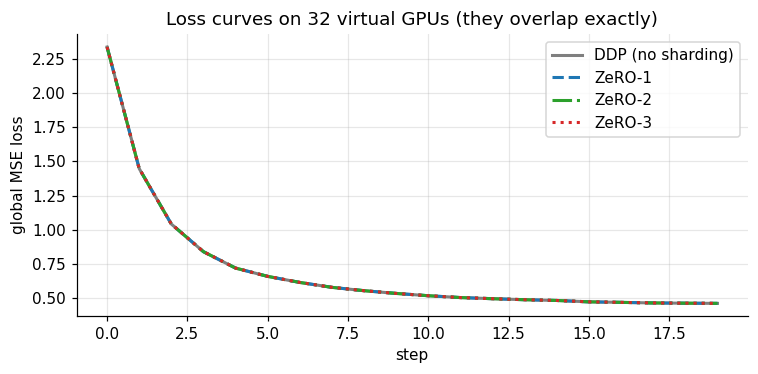

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for s, ls in zip(z.STAGES, ["-", "--", "-.", ":"]):
    ax.plot(results[s]["losses"], ls, color=COLORS[s], label=z.STAGE_LABEL[s], lw=2)
ax.set(xlabel="step", ylabel="global MSE loss", title="Loss curves on 32 virtual GPUs (they overlap exactly)")
ax.legend()
fig.tight_layout(); fig.savefig("results/loss_curves.png"); plt.show()

**Data parallel = one big batch.** The session notes say that averaging gradients over $N$ GPUs gives the same update as one
GPU on an $N\times$ larger batch. Check: one virtual GPU with a batch of 256.

In [10]:
single = z.run("ddp", z.Config(world_size=1, hidden=cfg.hidden, layers=cfg.layers,
                               local_batch=cfg.local_batch * cfg.world_size, steps=cfg.steps, track_timeline=False))
d = max((a - b).abs().max().item() for a, b in zip(single["_master_full"], ref))
print(f"max |w(1 GPU, batch 256) - w(32 GPUs, batch 8 each)| = {d:.2e}")
print("loss, last 3 steps  1 GPU :", [round(x, 5) for x in single["losses"][-3:]])
print("loss, last 3 steps 32 GPUs:", [round(x, 5) for x in results["ddp"]["losses"][-3:]])

max |w(1 GPU, batch 256) - w(32 GPUs, batch 8 each)| = 3.27e-03
loss, last 3 steps  1 GPU : [0.4639, 0.46201, 0.46077]
loss, last 3 steps 32 GPUs: [0.46391, 0.46201, 0.46079]


The two match to bf16 precision. They aren't bit-identical because a bf16 matmul over 256 rows adds the numbers in a
different order than 32 separate 8-row matmuls followed by an all-reduce.

## 6. Memory per GPU: measured vs predicted

All ranks live in one OS process, so OS memory counters can't separate them. Instead each rank registers every state
tensor it allocates and frees (`MemTracker` in `zero_sim.py`). The *peak model state* is the largest total ever held
by one rank (activations excluded, since ZeRO doesn't touch them).

In [11]:
rows = []
for s in z.STAGES:
    r = results[s]
    pred = r["memory"]["predicted_bytes"]
    rows.append({
        "strategy": z.STAGE_LABEL[s],
        "predicted bytes/param": sum(z.bytes_per_param(s, cfg.world_size).values()),
        "measured bytes/param (peak)": r["memory"]["peak_model_state_bytes"] / psi,
        "predicted MiB": sum(pred.values()) / MiB,
        "measured peak MiB": r["memory"]["peak_model_state_bytes"] / MiB,
        "between steps MiB": sum(v for k, v in r["memory"]["end_of_step_bytes"].items() if k != "activations") / MiB,
        "saving vs DDP": results["ddp"]["memory"]["peak_model_state_bytes"] / r["memory"]["peak_model_state_bytes"],
    })
mem_df = pd.DataFrame(rows).set_index("strategy").round(3)
mem_df

,predicted bytes/param,measured bytes/param (peak),predicted MiB,measured peak MiB,between steps MiB,saving vs DDP
strategy,,,,,,
DDP (no sharding),16.000,16.000,24.047,24.047,21.041,1.000
ZeRO-1,4.375,4.385,6.575,6.591,3.569,3.648
ZeRO-2,2.438,2.771,3.663,4.164,3.569,5.774
ZeRO-3,0.500,1.156,0.751,1.738,0.658,13.838


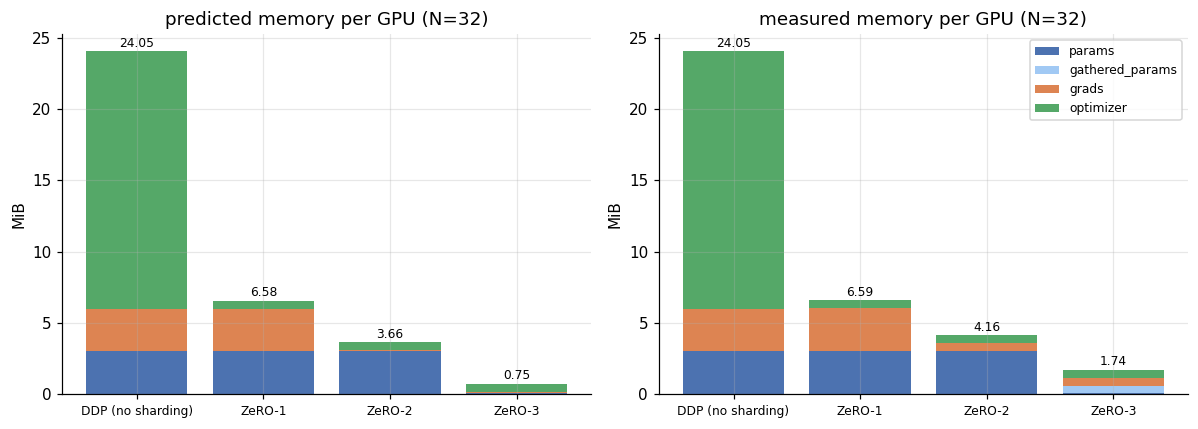

In [12]:
cats = ["params", "gathered_params", "grads", "optimizer"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, which in zip(axes, ["predicted", "measured"]):
    bottom = [0.0] * 4
    for c in cats:
        if which == "predicted":
            vals = [results[s]["memory"]["predicted_bytes"].get(c, 0) / MiB for s in z.STAGES]
        else:
            vals = [results[s]["memory"]["peak_by_cat"].get(c, 0) / MiB for s in z.STAGES]
        ax.bar([z.STAGE_LABEL[s] for s in z.STAGES], vals, bottom=bottom, color=CAT_COLORS[c], label=c)
        bottom = [b + v for b, v in zip(bottom, vals)]
    for i, b in enumerate(bottom):
        ax.text(i, b + 0.3, f"{b:.2f}", ha="center", fontsize=8)
    ax.set(title=f"{which} memory per GPU (N=32)", ylabel="MiB")
    ax.tick_params(axis="x", labelsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig("results/memory_per_gpu.png"); plt.show()

Measured and predicted agree, except for one small extra in ZeRO-2 and ZeRO-3: **the working set**.
* ZeRO-2 produces one layer's **full** gradient before it's reduce-scattered and freed. That's 0.5 MiB here, the size of
  one "bucket".
* ZeRO-3 also holds one layer's **gathered** weights while it computes with them, and in the backward pass the gathered
  weights and the full gradient are alive at the same time.

So the real floor for ZeRO-3 is $16\Psi/N$ **plus** one or two layers held in full. That's why real systems keep layers (FSDP
units) small and prefetch only the next one.

### Memory over one training step (rank 0)

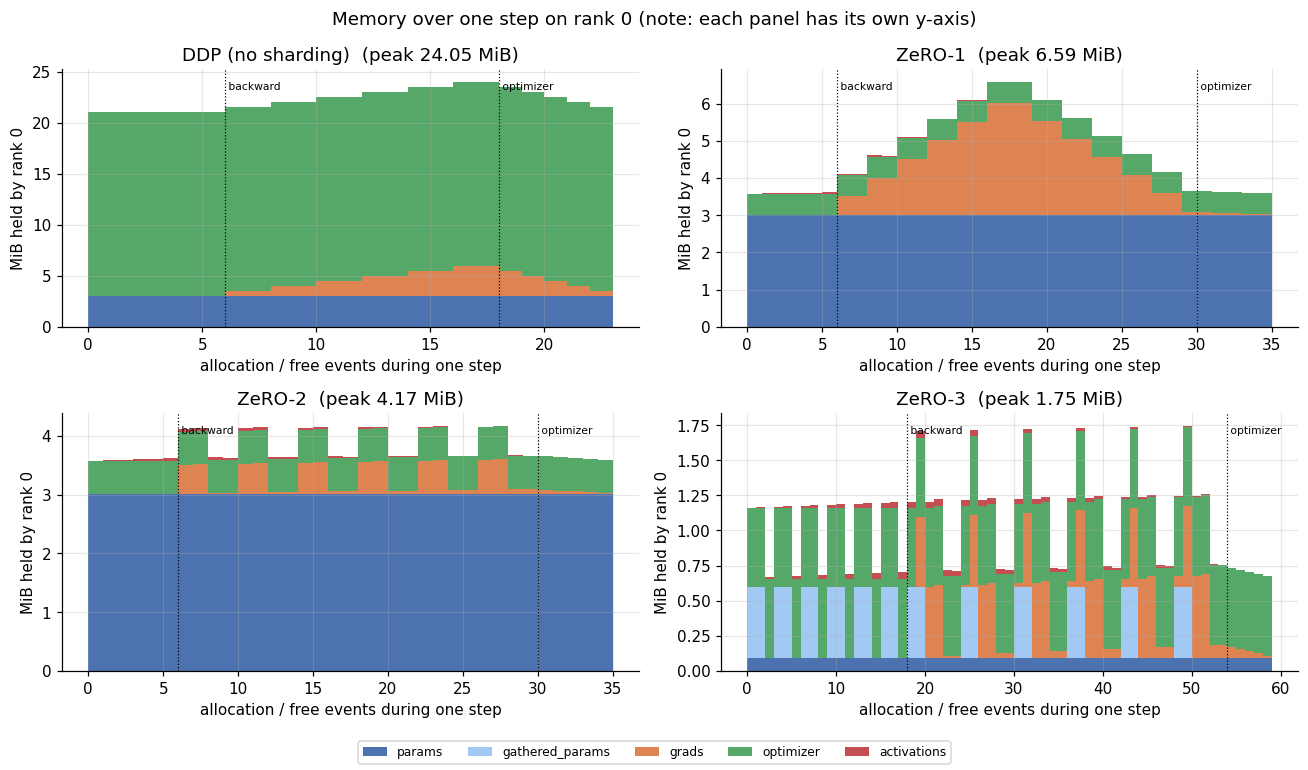

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
last = cfg.steps - 1
for ax, s in zip(axes.flat, z.STAGES):
    tl = [e for e in results[s]["timeline"] if e["step"] == last]
    xs = range(len(tl))
    ys = [[e[c] / MiB for e in tl] for c in z.MemTracker.CATEGORIES]
    ax.stackplot(xs, ys, labels=z.MemTracker.CATEGORIES, colors=[CAT_COLORS[c] for c in z.MemTracker.CATEGORIES],
                 step="post")
    ax.set(title=f"{z.STAGE_LABEL[s]}  (peak {max(sum(e[c] for c in z.MemTracker.CATEGORIES) for e in tl) / MiB:.2f} MiB)",
           xlabel="allocation / free events during one step", ylabel="MiB held by rank 0")
    # mark phase boundaries
    for i, e in enumerate(tl):
        if e["label"].startswith("bwd") and (i == 0 or not tl[i - 1]["label"].startswith("bwd")):
            ax.axvline(i, color="k", lw=0.8, ls=":"); ax.text(i, ax.get_ylim()[1] * 0.92, " backward", fontsize=7)
        if e["label"].startswith("step") and (i == 0 or not tl[i - 1]["label"].startswith("step")):
            ax.axvline(i, color="k", lw=0.8, ls=":"); ax.text(i, ax.get_ylim()[1] * 0.92, " optimizer", fontsize=7)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=8)
fig.suptitle("Memory over one step on rank 0 (note: each panel has its own y-axis)")
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig("results/memory_timeline.png"); plt.show()

How to read these:
* **DDP**: the orange gradients grow layer by layer during backward and stay until the optimizer frees them. The green
  optimizer block is the largest part (12 of 16 bytes).
* **ZeRO-1**: the green block shrinks to 1/32. The full gradients still build up during backward, because they're only
  reduced after backward finishes.
* **ZeRO-2**: each layer's full gradient appears and disappears straight away (the orange spikes). Only the 1/32 slice stays.
* **ZeRO-3**: the light-blue spikes are one layer's weights gathered just in time, used, and freed. The blue
  "params" layer is only 1/32 of the model.

## 7. How memory scales with the number of GPUs (measured)

Same model, $N = 1, 2, 4, 8, 16, 32$ virtual GPUs. Dashed lines are the formulas, dots are measurements.

In [14]:
sweep = []
for n in [1, 2, 4, 8, 16, 32]:
    c = z.Config(world_size=n, hidden=cfg.hidden, layers=cfg.layers, local_batch=cfg.local_batch,
                 steps=2, warmup_steps=1, track_timeline=False)
    for s in z.STAGES:
        r = z.run(s, c)
        sweep.append({"N": n, "stage": s, "measured": r["memory"]["peak_model_state_bytes"] / r["num_params_padded"],
                      "predicted": sum(z.bytes_per_param(s, n).values()), "comm_P": r["comm_in_P"]})
sweep_df = pd.DataFrame(sweep)
sweep_df.pivot(index="N", columns="stage", values="measured")[z.STAGES].round(2)

stage,ddp,zero1,zero2,zero3
N,,,,
1,16.0,16.33,16.33,16.33
2,16.0,10.17,9.33,8.50
4,16.0,7.08,5.83,4.58
8,16.0,5.54,4.08,2.62
16,16.0,4.77,3.21,1.65
32,16.0,4.39,2.77,1.16


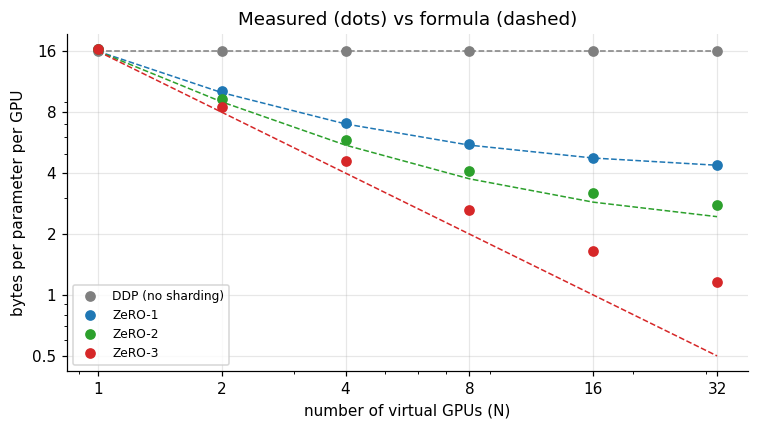

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
for s in z.STAGES:
    d = sweep_df[sweep_df.stage == s]
    ax.plot(d.N, d.predicted, "--", color=COLORS[s], lw=1)
    ax.plot(d.N, d.measured, "o", color=COLORS[s], label=z.STAGE_LABEL[s])
ax.set(xscale="log", yscale="log", xlabel="number of virtual GPUs (N)", ylabel="bytes per parameter per GPU",
       title="Measured (dots) vs formula (dashed)")
ax.set_xticks([1, 2, 4, 8, 16, 32], ["1", "2", "4", "8", "16", "32"])
ax.set_yticks([0.5, 1, 2, 4, 8, 16], ["0.5", "1", "2", "4", "8", "16"])
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("results/memory_vs_N.png"); plt.show()

## 8. Communication: how much each GPU sends per step

Byte counts use the standard ring-algorithm formulas (what NCCL does): all-reduce sends $2\frac{N-1}{N}S$,
reduce-scatter and all-gather send $\frac{N-1}{N}S$ each. Times are measured wall-clock time inside the gloo call,
averaged over ranks.

In [16]:
rows = []
for s in z.STAGES:
    for tag, c in results[s]["comm"].items():
        rows.append({"strategy": z.STAGE_LABEL[s], "collective": tag, "calls/step": int(c["calls_per_step"]),
                     "MiB sent/step": c["bytes_sent_per_step"] / MiB, "in units of P": c["bytes_sent_per_step"] / (2 * psi),
                     "ms/step": c["time_s_per_step_mean_over_ranks"] * 1e3})
comm_df = pd.DataFrame(rows).set_index(["strategy", "collective"]).round(3)
comm_df

calls/step  MiB sent/step  \
strategy          collective                                                 
DDP (no sharding) grad all-reduce                         6          5.824   
ZeRO-1            grad reduce-scatter                     6          2.912   
                  param all-gather (after step)           6          2.912   
ZeRO-2            grad reduce-scatter                     6          2.912   
                  param all-gather (after step)           6          2.912   
ZeRO-3            grad reduce-scatter                     6          2.912   
                  param all-gather (bwd)                  6          2.912   
                  param all-gather (fwd)                  6          2.912   

                                                 in units of P  ms/step  
strategy          collective                                             
DDP (no sharding) grad all-reduce                        1.938  872.165  
ZeRO-1            grad reduce-scatter                    0.969  778.365  
                  param all-gather (after step)          0.969  366.294  
ZeRO-2            grad reduce-scatter                    0.969  887.600  
                  param all-gather (after step)          0.969  359.188  
ZeRO-3            grad reduce-scatter                    0.969  872.856  
                  param all-gather (bwd)                 0.969  402.890  
                  param all-gather (fwd)                 0.969  383.640

In [17]:
summary_comm = pd.DataFrame({
    "measured (x P)": [results[s]["comm_in_P"] for s in z.STAGES],
    "predicted (x P)": [results[s]["comm_in_P_predicted"] for s in z.STAGES],
    "textbook": ["2P", "2P", "2P", "3P"],
}, index=[z.STAGE_LABEL[s] for s in z.STAGES]).round(3)
summary_comm

,measured (x P),predicted (x P),textbook
DDP (no sharding),1.938,1.938,2P
ZeRO-1,1.938,1.938,2P
ZeRO-2,1.938,1.938,2P
ZeRO-3,2.906,2.906,3P


### Time per step: where does it go?

Every rank is a thread on a 12-core laptop CPU and every byte travels over loopback TCP, so these absolute times are far
slower than real GPUs. The *differences* between stages are what to look at.

,forward,backward,optimizer,communication,total step,other (sync/overhead)
DDP (no sharding),43.1,285.3,213.4,872.2,1461.3,47.3
ZeRO-1,38.9,370.0,60.6,1144.7,1662.2,48.1
ZeRO-2,44.4,287.5,61.2,1246.8,1695.0,55.1
ZeRO-3,39.2,293.0,55.5,1659.4,2090.0,42.9


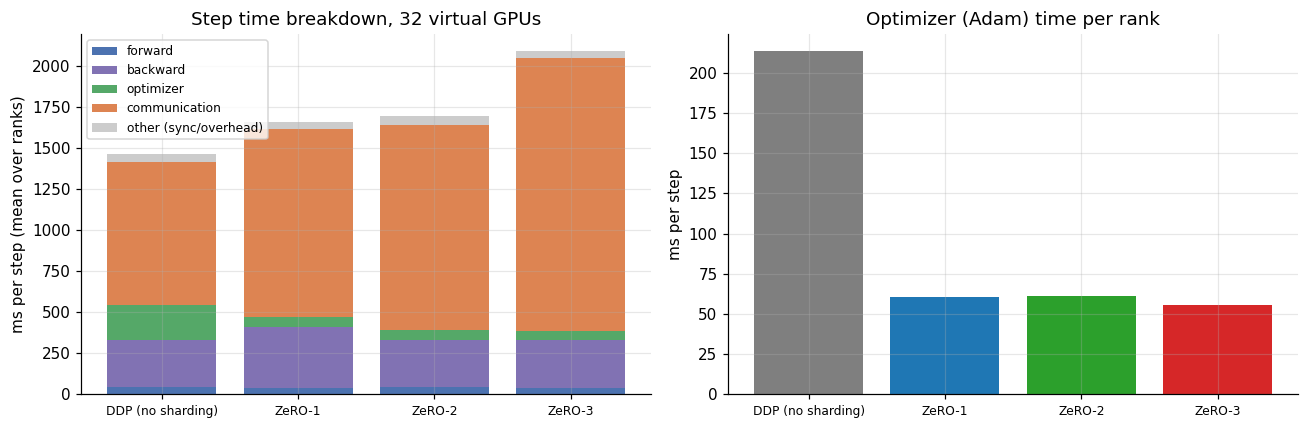

In [18]:
parts = ["forward_compute_s", "backward_compute_s", "optimizer_s", "comm_s"]
time_df = pd.DataFrame({s: {p: results[s]["timing_per_step"][p] * 1e3 for p in parts + ["step_s"]} for s in z.STAGES}).T
time_df["other (sync/overhead)"] = time_df["step_s"] - time_df[parts].sum(axis=1)
time_df.index = [z.STAGE_LABEL[s] for s in z.STAGES]
time_df.columns = ["forward", "backward", "optimizer", "communication", "total step", "other (sync/overhead)"]
display(time_df.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bottom = [0.0] * 4
for col, colr in zip(["forward", "backward", "optimizer", "communication", "other (sync/overhead)"],
                     ["#4c72b0", "#8172b3", "#55a868", "#dd8452", "#cccccc"]):
    vals = time_df[col].clip(lower=0).tolist()
    axes[0].bar(time_df.index, vals, bottom=bottom, label=col, color=colr)
    bottom = [b + v for b, v in zip(bottom, vals)]
axes[0].set(ylabel="ms per step (mean over ranks)", title="Step time breakdown, 32 virtual GPUs")
axes[0].legend(fontsize=8); axes[0].tick_params(axis="x", labelsize=8)
axes[1].bar(time_df.index, time_df["optimizer"], color=[COLORS[s] for s in z.STAGES])
axes[1].set(ylabel="ms per step", title="Optimizer (Adam) time per rank")
axes[1].tick_params(axis="x", labelsize=8)
fig.tight_layout(); fig.savefig("results/time_breakdown.png"); plt.show()

What the timings show:
* **Forward and backward compute are the same work for every stage.** Each rank still pushes its own 8 samples through the
  whole model. ZeRO doesn't split the compute; it splits the storage. The small differences between the purple bars are
  noise from 32 threads competing for 12 cores.
* **The optimizer step gets cheaper with ZeRO-1/2/3**, because each rank runs Adam on only 1/32 of the parameters. It doesn't
  fall a full 32x here, because per-call Python overhead and 32 threads sharing 12 cores dominate at this small size.
* **ZeRO-3 is the slowest.** It adds a second all-gather of the weights (forward and backward), which is the extra $1P$.
* Gloo's reduce-scatter on loopback isn't bandwidth-optimal. It takes about as long as a full all-reduce, so ZeRO-1/2 look
  slower than DDP here even though they send the same bytes. With NCCL on real GPUs, reduce-scatter plus all-gather costs
  about the same as one all-reduce. Byte volume is the number that carries over from this laptop to real hardware.

### Scaling the communication back up to the 30B model

Applying the measured multiples of P to the V5 model (P = 60 GB) and the bandwidths from the session:

In [19]:
P_GB = 60
bw = {"NVLink inside a node (450 GB/s)": 450, "InfiniBand between nodes (50 GB/s)": 50}
pd.DataFrame({k: [round(results[s]["comm_in_P"] * P_GB / v, 2) for s in z.STAGES] for k, v in bw.items()},
             index=[z.STAGE_LABEL[s] for s in z.STAGES]).rename_axis("seconds of communication per step")

,NVLink inside a node (450 GB/s),InfiniBand between nodes (50 GB/s)
seconds of communication per step,,
DDP (no sharding),0.26,2.33
ZeRO-1,0.26,2.33
ZeRO-2,0.26,2.33
ZeRO-3,0.39,3.49


## 9. Summary

In [20]:
summary = pd.DataFrame({
    "shards": ["nothing", "optimizer states", "optimizer + grads", "optimizer + grads + params"],
    "bytes/param (formula)": [round(sum(z.bytes_per_param(s, 32).values()), 3) for s in z.STAGES],
    "bytes/param (measured)": [round(results[s]["memory"]["peak_model_state_bytes"] / psi, 3) for s in z.STAGES],
    "memory vs DDP": [f"{results[s]['memory']['peak_model_state_bytes'] / results['ddp']['memory']['peak_model_state_bytes']:.1%}" for s in z.STAGES],
    "comm (x P)": [round(results[s]["comm_in_P"], 2) for s in z.STAGES],
    "optimizer ms": [round(results[s]["timing_per_step"]["optimizer_s"] * 1e3, 1) for s in z.STAGES],
    "step ms": [round(results[s]["timing_per_step"]["step_s"] * 1e3, 1) for s in z.STAGES],
    "same weights as DDP": [check.iloc[i, 1] == 0 for i in range(4)],
}, index=[z.STAGE_LABEL[s] for s in z.STAGES])
summary.to_csv("results/summary.csv")
summary

,shards,bytes/param (formula),bytes/param (measured),memory vs DDP,comm (x P),optimizer ms,step ms,same weights as DDP
DDP (no sharding),nothing,16.000,16.000,100.0%,1.94,213.4,1461.3,True
ZeRO-1,optimizer states,4.375,4.385,27.4%,1.94,60.6,1662.2,True
ZeRO-2,optimizer + grads,2.438,2.771,17.3%,1.94,61.2,1695.0,True
ZeRO-3,optimizer + grads + params,0.500,1.156,7.2%,2.91,55.5,2090.0,True


**Takeaways**
1. **ZeRO-1** removes the biggest block (the 12-byte optimizer state) at no extra communication. It's always worth turning on.
2. **ZeRO-2** also shards gradients, again at no extra communication. The price is that gradients must be reduce-scattered
   *during* backward (bucket by bucket), which makes gradient accumulation and overlap a little more involved.
3. **ZeRO-3** shards everything, so memory falls as $1/N$ with no floor. The cost is 50% more communication (3P instead of 2P)
   and an all-gather in front of every layer, which must be prefetched or it stalls compute.
4. All four produce **bit-identical weights**. ZeRO changes where state lives, not what is computed.